In [19]:
import pandas as pd
import numpy as np
from astropy import units as u
from galpy.orbit import Orbit
from galpy.potential import MWPotential2014
from galpy.actionAngle import actionAngleStaeckel, estimateDeltaStaeckel
import matplotlib.pyplot as plt

In [16]:
data = pd.read_csv("../3_spectroscopic_xmatch/GSPSPEC_input_catalogue.csv")
phasespace = [
    data["ra"].to_numpy() * u.degree,
    data["dec"].to_numpy() * u.degree,
    data["dist"].to_numpy() / 1e3 * u.kpc,
    data["pmra"].to_numpy() * u.mas / u.yr,
    data["pmdec"].to_numpy() * u.mas / u.yr,
    data["rv"].to_numpy() * u.km / u.s
]

In [48]:
orbits = Orbit(phasespace, radec=True, ro=8.0, vo=220.0)

jr = orbits.jr(pot=MWPotential2014, analytic=True, type="staeckel")
lz = orbits.Lz()
jz = orbits.jz(pot=MWPotential2014, analytic=True, type="staeckel")

e = orbits.e(pot=MWPotential2014, analytic=True, type="staeckel")
zmax = orbits.zmax(pot=MWPotential2014, analytic=True, type="staeckel")
rperi = orbits.rperi(pot=MWPotential2014, analytic=True, type="staeckel")
rap = orbits.rap(pot=MWPotential2014, analytic=True, type="staeckel")
rguid = orbits.rguiding(pot=MWPotential2014, ro=8.0, vo=220.0, use_physical=True)

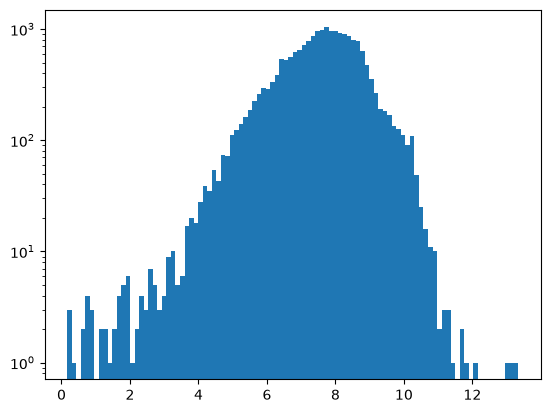

In [49]:
plt.hist(rguid, bins=100)
plt.yscale("log")
plt.show()